# Lesson 10b: Multi-Atomic Cluster Expansion (MACE)

**What you will learn**

- How MACE combines the **density trick** of the atomic cluster expansion (ACE,
  Lesson 10a) with **equivariant message passing** (Lessons 06a and 08a): every
  MACE message is an ACE itself.
- The anatomy of the MACE layer, equation by equation: the **$A$-basis** built
  from radial functions, spherical harmonics and learned neighbor features, the
  higher-order $B$-features from generalized Clebsch–Gordan contractions,
  and the linear message, update and readout.
- How body order is counted: a layer with correlation order $\nu = 3$ gives
  4-body features, and two such layers reach 13-body features.
- The **design-space** view, which places SchNet, DimeNet, NequIP, BOTNet,
  linear ACE and MACE in one framework.
- Why MACE is **fast**.

**Prerequisites:**

- [Lessons 03a](03a_tensor_products_theory.ipynb) and
  [03b](03b_tensor_products_e3nn.ipynb): Tensor products and Clebsch–Gordan
  coefficients,
- [Lesson 06a](06a_equivariant_convolution.ipynb): Equivariant convolution,
- [Lesson 08a](08a_nequip_theory.ipynb): The NequIP architecture,
- [Lesson 10a](10a_ace_theory.ipynb): ACE, the density trick and the
  $B$-basis.

In [1]:
import sys; sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import torch
from e3nn import o3

torch.manual_seed(0)
# This is a theory notebook and the code base is tiny. So, we use float64
# everywhere and the numerical checks stay within machine precision.
torch.set_default_dtype(torch.float64)
device = "cpu"
print(f"torch {torch.__version__}")

torch 2.7.1+cu126


## From ACE and NequIP to MACE

Lesson 10a ended with citing two methods for reaching a high body order in the
design space:

- **ACE**, which reaches any body order in a single, strictly local layer. Its
  basis is fixed, its readout is linear, and its element channels grow as
  $S^\nu$ for $S$ chemical elements.
- **Equivariant message passing** framework, which allows models to learn their
  chemical features from data and provide accurate predictions. For example,
  NequIP's message is 2-body, but its body order can grow only by stacking
  message passing layers ($T \approx 5$). Every layer also adds one cutoff to
  the model's receptive field, making its computational cost more expensive.

[MACE
](https://proceedings.neurips.cc/paper_files/paper/2022/file/4a36c3c51af11ed9f34615b81edb5bbc-Paper-Conference.pdf)
combines ACE and equivariant message passing by turning each message into a
cluster expansion and thus, follows the standard message-passing framework with
the state of node $i$ in layer $t$, $\sigma_i^{(t)}$, defined as

$$\sigma_i^{(t)} = \big(\vec r_i,\, z_i,\, h_i^{(t)}\big).$$

Here, $\vec r_i \in \mathbb{R}^3$, is the position of atom $i$, $z_i$,
represents its chemical element and $h_i^{(t)}$ stands for its learnable
features. A forward pass in MACE involves three steps: Message construction,
update, and readout. The message construction pools all messages from the
neighboring atoms, $\mathcal N(i)$, of a central atom $i$, within a cutoff
radius as,

$$m_i^{(t)} = \bigoplus_{j \in \mathcal N(i)} M_t\big(\sigma_i^{(t)}, \sigma_j^{(t)}\big),$$

where $M_t$ is a learnable message function and $\bigoplus$ is a
permutation-invariant pooling operation, such as summation. The **update** step
is defined as,

$$h_i^{(t+1)} = U_t\big(\sigma_i^{(t)}, m_i^{(t)}\big).$$

All features are $O(3)$-equivariant. Each feature entry, $h^{(t)}_{i,kLM}$,
often carries a channel index $k$, an angular momentum $L$ and a component $M$,
and transforms under $Q \in O(3)$ with the Wigner matrix $D^{(L)}(Q)$. Entries
with $L = 0$ are invariant scalars and entries with $L > 0$ are equivariant.

After $T$ message-passing layers, the readout, $R_t$, maps the node states,
$\sigma_i^{(t)}$, to the site energies, $E_i$, as

$$E_i = \sum_{t=1}^{T} R_t\big(\sigma_i^{(t)}\big).$$

## Body-ordered messages in MACE

MACE's key ingredient is its message function, $M_t$. Instead of a 2-body
message, which depends on one neighbor at a time, MACE's message is a
**hierarchical body-order expansion**:

$$m_i^{(t)} = \sum_j u_1\big(\sigma_i^{(t)}; \sigma_j^{(t)}\big) + \sum_{j_1, j_2} u_2\big(\sigma_i^{(t)}; \sigma_{j_1}^{(t)}, \sigma_{j_2}^{(t)}\big) + \cdots + \sum_{j_1, \dots, j_\nu} u_\nu\big(\sigma_i^{(t)}; \sigma_{j_1}^{(t)}, \dots, \sigma_{j_\nu}^{(t)}\big),$$

which is comprised of trainable functions, $u_1, \dots, u_\nu$, and sums over
the neighbors of $i$. The hyperparameter $\nu$ is the maximum correlation
order of the message which corresponds to its body order minus 1 with respect
to each node state. Two notes about the MACE messages should be highlighted:

1. The sums over $j_1, \dots, j_\nu$ are **unrestricted**: they include
   self-interaction terms, corresponding to cases such as $j_1 = j_2$. This is a
   choice behind the density trick (Lesson 10a) which allows us to circumvent
   the exponential cost of expensive terms with the correlation order $\nu$.
   DimeNet, by contrast, sums explicitly over triplets $j_1 < j_2$.
2. The atomic states at each layer, $\sigma_j^{(t)}$, carry many-body
   information from earlier layers. As such, the body order with respect to the positions
   can be much higher than $\nu + 1$. We will return to this point in
   the proceeding sections.

Each MACE layer involves three main stages: calculation of the $A$-basis,
creating the $B$-basis and computing a linear message. These phases mirror the
three steps of ACE framework in Lesson 10a: the atomic base, the symmetrized
products and the linear mapping. In the following sections, we will go through
each of these steps in detail.

## MACE layer

### $A$-basis functions as pooled 2-body features

Each MACE layer embeds the edges with a learnable radial basis $R^{(t)}$, the
spherical harmonics $Y^{(l)}_m$ and a learnable linear embedding $W^{(t)}$ of
the sender node's features. Then, it pools the resulting features over
contributions from the neighboring atoms, $\mathcal N(i)$,

$$A^{(t)}_{i,kl_3m_3} = \sum_{l_1m_1,\,l_2m_2} C^{(l_3,m_3)}_{(l_1,m_1)(l_2,m_2)} \sum_{j \in \mathcal N(i)} R^{(t)}_{kl_1l_2l_3}(r_{ji})\, Y^{(l_1)}_{m_1}(\hat r_{ji}) \sum_{\tilde k} W^{(t)}_{k\tilde kl_2}\, h^{(t)}_{j,\tilde kl_2m_2}.$$

Here $C^{(l_3,m_3)}_{(l_1,m_1)(l_2,m_2)}$ are the Clebsch-Gordan (CG)
coefficients (Lesson 03a), $r_{ji}$ is the interatomic distance and $\hat
r_{ji}$ the unit vector along the bond. The aforementioned equation is the
**e3nn point convolution** of Lesson 06a: a weighted tensor product of the edge
spherical harmonics with the neighbor features, summed over the neighbors. The
radial weights $R^{(t)}_{kl_1l_2l_3}$, coming from Bessel functions, times a
smooth polynomial cutoff, fed through an MLP (Lesson 05b). The experiments in
the [MACE manuscript
](https://proceedings.neurips.cc/paper_files/paper/2022/file/4a36c3c51af11ed9f34615b81edb5bbc-Paper-Conference.pdf)
use 8 Bessel functions, a polynomial envelope with $p = 5$ and an MLP of size
$[64, 64, 64, 1024]$ with SiLU activations.

In the **first MACE layer**, the node features are just the (invariant) chemical
elements, $z_j$ which simplifies the $A$-basis to

$$A^{(1)}_{i,kl_1m_1} = \sum_{j \in \mathcal N(i)} R^{(1)}_{kl_1}(r_{ji})\, Y^{(l_1)}_{m_1}(\hat r_{ji})\, W^{(1)}_{kz_j}.$$

This is equivalent to the **ACE atomic basis** of Lesson 10a, $A_{i,nlm} =
\sum_j R_{nl}(r_{ij})\, Y^{(l)}_m(\hat r_{ij})$, with two changes: the radial
index $n$ becomes a learnable channel $k$, and a learned weight per element
replaces the discrete species index. No tensor product with neighboring features
is needed here, which makes the first layer computationally cheap. 

### $B$-basis functions as higher-order tensor product features

Another key operation in MACE is to multiply $\nu$ copies of the $A$-features
and couple their products back to the irreps space via **generalized CG
coefficients**:

$$B^{(t)}_{i,\eta_\nu kLM} = \sum_{\boldsymbol{lm}} \mathcal C^{LM}_{\eta_\nu,\boldsymbol{lm}} \prod_{\xi=1}^{\nu} \sum_{\tilde k} w^{(t)}_{k\tilde kl_\xi}\, A^{(t)}_{i,\tilde kl_\xi m_\xi}, \qquad \boldsymbol{lm} = (l_1m_1, \dots, l_\nu m_\nu).$$

The index $\eta_\nu$ enumerates the ways of coupling $l_1, \dots, l_\nu$ to the
output symmetry $L$, and the weights, $w^{(t)}_{k\tilde kl_\xi}$, mix the
channels. The generalized CG coefficients, $\mathcal
C^{LM}_{\eta_\nu,\boldsymbol{lm}}$, are iterated pairwise CG contractions.
Lesson 10a used a special case of generalized CGs, the Wigner $3j$ symbol, that
couples three atomic bases to $L = 0$. The CG coefficients are very sparse and
are often precomputed. Therefore, the $A$-basis coupling costs a few dense
contractions at the run time. Furthermore, the creation of $B$-basis involves no
summation over pairs or triplets of neighbors. In the words, the computationally
expensive multi-dimensional sums over all triplets, quadruplets, etc., are
circumvented. This is the density trick of Lesson 10a, now connecting the
learnable equivariant features to the outputs of any symmetry $L$, not just only
invariant scalars ($L = 0$).

### Message, update and readout

MACE creates its messages as a **linear** combination of the $B$-features,

$$m^{(t)}_{i,kLM} = \sum_{\nu} \sum_{\eta_\nu} W^{(t)}_{z_ikL,\eta_\nu}\, B^{(t)}_{i,\eta_\nu kLM}.$$

The weights depend on the chemical element $z_i$ of the *receiving* atom and on
the message symmetry $L$, and they build each $u_\nu$ of Eq. (7) implicitly.
Under mild conditions, the $B$-features form a complete basis of many-body
interactions ([Dusson et al., *J. Comput. Phys.* **454**, 110946 (2022)](https://doi.org/10.1016/j.jcp.2022.110946), Lesson 10a). The expansion of Eq. (11) is therefore
systematic: it "can in principle be converged to represent any smooth
$(\nu+1)$-body equivariant mapping in the limit of infinitely many features".

The update is linear with a residual connection (MACE Eq. (12)):

$$h^{(t+1)}_{i,kLM} = \sum_{\tilde k} W^{(t)}_{kL,\tilde k}\, m^{(t)}_{i,\tilde kLM} + \sum_{\tilde k} W^{(t)}_{z_ikL,\tilde k}\, h^{(t)}_{i,\tilde kLM}.$$

Finally, every layer adds a site-energy term computed from its **invariant**
($L = 0$) features (MACE Eq. (13)):

$$E_i = E_i^{(0)} + E_i^{(1)} + \dots + E_i^{(T)}, \qquad E_i^{(t)} = \begin{cases} \sum_{\tilde k} W^{(t)}_{\text{readout},\tilde k}\, h^{(t)}_{i,\tilde k00} & t < T, \\[4pt] \mathrm{MLP}^{(t)}_{\text{readout}}\big(\{h^{(t)}_{i,k00}\}_k\big) & t = T. \end{cases}$$

The readouts of all layers but the last are linear, which keeps the energy
body-ordered. The last layer uses a one-layer MLP (with 16 hidden units in the
experiments of the paper).

## Body-order accounting: why two layers are enough

How many atoms does a node feature depend on, counted as a product of
positions? [Kovács et al., *J. Chem. Phys.* **159**, 044118 (2023)](https://doi.org/10.1063/5.0155322) (Sec. II B) count this for the standard setting
$\nu = 3$:

- **Layer 1.** Each factor of the $\nu = 3$ product of Eq. (10) is a 2-body
  function of the central atom and one neighbor. Their product depends on the
  central atom and three neighbors, so the node features after the first layer
  are **4-body** functions.
- **Layer 2.** The one-particle basis of Eq. (8) takes the 4-body features of a
  neighbor and adds the central atom: $4 + 1 = 5$ bodies. The product of three
  such factors shares the central atom, which gives $3 \times 4 + 1 =
  13$-body features.

In general, let $b_t$ be the body order of the node features after layer $t$,
with $b_0 = 1$ for the element embedding alone. Each layer applies

$$b_t = \nu\, b_{t-1} + 1.$$

The body order therefore grows **geometrically** with the number of layers. For
the 2-body messages of conventional message-passing networks ($\nu = 1$), it
grows only linearly, $b_t = t + 1$. The body order comes from $\nu$ (local
products), while the receptive field comes from $T$ (message hops). MACE
decouples the two.

The paper tests this on the 3BPA benchmark (MACE Fig. 1). NequIP and BOTNet,
which pass 2-body messages, need up to five layers before their accuracy
converges, while MACE converges at two. The learning curves on rMD17 aspirin
(MACE Fig. 2) separate the two mechanisms. Raising $\nu$ at fixed $L = 0$
makes the curves steeper: the slope of the log-log learning curve goes from
$-0.33$ ($\nu = 1$) to $-0.51$ ($\nu = 2$) and $-0.64$ ($\nu = 3$). Adding
equivariance ($L > 0$) at $\nu = 3$ shifts the curves but leaves the slope
unchanged.

Let's compute the body order with this recursion and plot it against the number
of layers.

two MACE layers with nu = 3: 13-body features


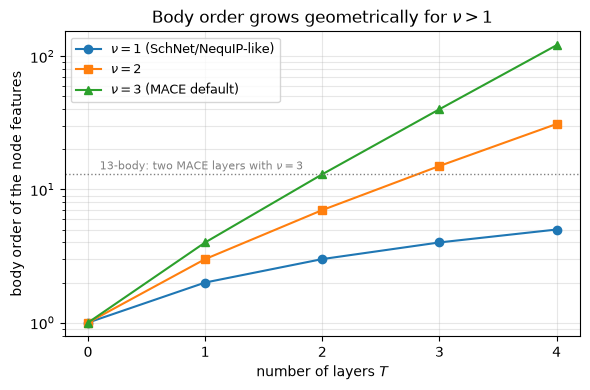

In [2]:
def body_order(nu, T):
    """Body order of the node features after T layers: b_t = nu * b_(t-1) + 1, b_0 = 1."""
    b = 1
    for _ in range(T):
        b = nu * b + 1
    return b


print(f"two MACE layers with nu = 3: {body_order(3, 2)}-body features")

# Body order against the number of layers for nu = 1, 2, 3
layers = list(range(5))
fig, ax = plt.subplots(figsize=(6, 4))
for nu, marker, note in [(1, "o", " (SchNet/NequIP-like)"), (2, "s", ""), (3, "^", " (MACE default)")]:
    ax.semilogy(layers, [body_order(nu, T) for T in layers], marker + "-", label=rf"$\nu = {nu}${note}")
ax.axhline(13, color="gray", ls=":", lw=1)
ax.text(0.1, 14, r"13-body: two MACE layers with $\nu = 3$", fontsize=8, color="gray")
ax.set_xlabel("number of layers $T$")
ax.set_ylabel("body order of the node features")
ax.set_xticks(layers)
ax.set_title(r"Body order grows geometrically for $\nu > 1$")
ax.legend(fontsize=9)
ax.grid(alpha=0.3, which="both")
fig.tight_layout()

The receptive field tells the other half of the story. Information travels one
cutoff $r_c$ per layer, so a model with $T$ layers sees atoms up to $T r_c$ away
from the central atom. Let's compare a NequIP-like model ($T = 5$, $r_c = 4$ Å)
with MACE ($T = 2$, $r_c = 5$ Å).

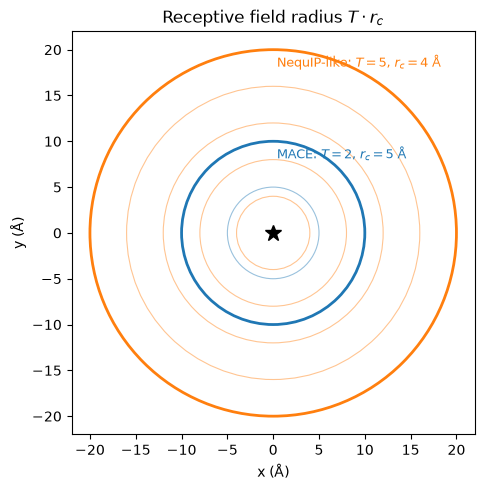

In [3]:
fig, ax = plt.subplots(figsize=(5, 5))
for T, r_c, color, name in [(5, 4.0, "C1", r"NequIP-like: $T = 5$, $r_c = 4$ Å"),
                            (2, 5.0, "C0", r"MACE: $T = 2$, $r_c = 5$ Å")]:
    # One circle per layer; the outermost one (t = T) bounds the receptive field
    for t in range(1, T + 1):
        ax.add_patch(plt.Circle((0, 0), t * r_c, fill=False, color=color,
                                lw=2 if t == T else 0.8, alpha=1.0 if t == T else 0.45))
    ax.text(0.4, T * r_c - 1.9, name, color=color, fontsize=9)

# The central atom
ax.plot(0, 0, "k*", markersize=12)
ax.set_xlim(-22, 22)
ax.set_ylim(-22, 22)
ax.set_aspect("equal")
ax.set_xlabel("x (Å)")
ax.set_ylabel("y (Å)")
ax.set_title(r"Receptive field radius $T \cdot r_c$")
fig.tight_layout()

This is why MACE parallelizes well. With $T = 2$, the receptive field has a
radius of $2 r_c = 10$ Å instead of 20 Å. When a large system is split into
domains on several GPUs, far less halo data must be exchanged at every MD step.

## The design-space view: one framework, many models

[Batatia et al., *Nat. Mach. Intell.* **7**, 56 (2025)](https://doi.org/10.1038/s42256-024-00956-x) turn this comparison into a framework, which they call
**Multi-ACE**. NequIP, BOTNet, MACE, linear ACE, SchNet, DimeNet and others are
all points in its design space. The construction extends the one-particle basis
of equivariant ACE to depend on the features of the previous layer (their
Eq. (2)):

$$\phi^{(t)}_{kvL}\big(\sigma_i^{(t)}, \sigma_j^{(t)}\big) = R^{(t)}_{kcl_1L}(r_{ji})\, Y^{(l_1)}_{m_1}(\hat r_{ji})\, T^{(t)}_{kcL}\big(h_j^{(t)}, \theta_i, \theta_j\big),$$

where $R$ are radial functions, $Y$ spherical harmonics, $T$ a generic node
embedding function, $v \equiv (l_1 m_1 c)$ a multi-index and $\theta$ fixed
node attributes such as the chemical element. Pooling and symmetrizing exactly
as in ACE gives the central **Multi-ACE equation** (their Eq. (4)):

$$m^{(t)}_{i,kLM} = \sum_{\eta} w^{(t)}_{i,k\eta L} \sum_{\boldsymbol v} \mathcal C^{LM}_{\eta,\boldsymbol v} \prod_{\xi=1}^{\nu} \sum_{j \in \mathcal N(i)} \phi^{(t)}_{kv_\xi L}\big(\sigma_i^{(t)}, \sigma_j^{(t)}\big),$$

followed by a linear update (their Eq. (5)). Every architecture is then a small
set of discrete choices: the number of layers $T$, the correlation order $\nu$,
the largest message symmetry $L_{\max}$ (invariant or equivariant messages),
the internal $l_{\max}$, how channels and elements are coupled, and where the
nonlinearities sit. Their Table 1, abridged to spherical models, reads:

| Model | internal $l_{\max}$ | update $L_{\max}$ | $\nu$ | $T$ | total correlation order | coupling |
|---|---|---|---|---|---|---|
| SOAP        | $\ge 3$ | $0$      | $2$      | $1$      | $\ge 3$        | $nlm$ |
| Linear ACE  | $\ge 1$ | $0$      | $\ge 2$  | $1$      | $\ge 3$        | $nlm$ |
| SchNet      | $0$     | $0$      | $1$      | $\ge 2$  | $T$            | $\emptyset$ |
| DimeNet     | $0$     | $0$      | $2$      | $\ge 2$  | $2T$           | $\emptyset$ |
| Cormorant   | $\ge 1$ | $\ge 1$  | $1$      | $\ge 2$  | $T$            | $lm$ |
| NequIP      | $\ge 1$ | $\ge 1$  | $1$      | $\ge 2$  | $T$            | $l_1 m_1 l_2 m_2$ |
| **MACE**    | $\ge 1$ | $\ge 0$  | $\ge 1$  | $\ge 1$  | $\sim \nu T + T$ | $l_1 m_1 l_2 m_2$ |

The "coupling" column lists the indices of the one-particle basis that are
coupled when the product basis is formed. Read row by row:

- **SchNet** is the corner $l_{\max} = 0$, $\nu = 1$: invariant 2-body
  messages.
- **DimeNet** adds angles, that is, $\nu = 2$ with invariant features only.
- **NequIP** is equivariant but keeps $\nu = 1$. It gains body order through
  depth and nonlinearities.
- **Linear ACE** uses a large $\nu$ in a single layer with a fixed basis.
- **MACE** is the general point with both $\nu > 1$ and $T > 1$.

### From NequIP to BOTNet

To find out which design choices matter, the paper simplifies NequIP into
**BOTNet** (body-ordered tensor network). BOTNet keeps NequIP's equivariant
tensor-product convolution and learnable radial basis, but its updates are
linear. The model is therefore body-ordered by construction. Three findings
stand out:

- BOTNet "maintains its accuracy on benchmark datasets": NequIP's nonlinear
  updates can be traded for an explicit body order. Within NequIP itself,
  however, "the choice of nonlinearity is crucial". Replacing SiLU with $\tanh$
  makes its results significantly worse.
- Linear ACE couples the element channels, and its basis grows as $S^\nu$. Most
  message-passing networks, MACE included, embed the elements into $k$ learned
  channels instead. These channels are not coupled in the product basis, so
  "the number of features does not depend on the number of chemical elements".
  MACE leaves the species dimension out of the tensor product of Eq. (10), which
  gives $\mathcal O(1)$ scaling in $S$ (MACE Sec. 5.2).
- Together with the learning curves of MACE Fig. 2, the picture is that there
  are two routes to accuracy, a higher $\nu$ or more layers $T$, and MACE takes
  a bit of both.

## Why MACE is fast

The reasons, collected from the sections above:

1. **No sums over neighbor tuples.** A higher body order costs a few dense
   contractions with precomputed sparse coefficients (Eq. (10)) on per-node
   arrays. There is never an explicit sum over pairs or triplets of neighbors.
2. **Two layers.** A high body order per layer replaces depth (MACE Fig. 1).
   Fewer layers mean fewer neighbor gathers, a smaller receptive field and an
   easier split of large systems over several GPUs.
3. **Edges once, nodes for the rest.** The expensive equivariant tensor product
   of Eq. (8) runs on the edges, and in the first layer it reduces to the cheap
   Eq. (9). The higher-order products of Eq. (10) run on the nodes, which are
   far fewer than the edges.
4. **$\mathcal O(1)$ in the number of elements.** Learned element embeddings
   replace the $S^\nu$ coupled element channels of linear ACE.
5. **Mostly linear algebra.** The message, the update and all but the last
   readout are linear. Apart from the polynomial products of Eq. (10), the only
   nonlinear functions are the radial MLP and the readout MLP of the last
   layer.

The paper reports state-of-the-art accuracy on the 3BPA benchmark after about
30 minutes of training on an NVIDIA A100 GPU, while a converged BOTNet model
takes more than a day to train.

## Summary

In this lesson, we have learned:

- **MACE is ACE inside message passing:** Each layer builds an atomic base
  $A^{(t)}$ from radial functions, spherical harmonics and learned neighbor
  embeddings (Eqs. (8) and (9)). Tensor products with generalized
  Clebsch–Gordan coefficients turn it into higher-order equivariant
  $B$-features (Eq. (10)) without any sum over neighbor tuples.
- **Linear message, update and readout:** Eqs. (11) to (13) are linear, except
  for the radial MLP and the readout MLP of the last layer. Each layer adds a
  site energy computed from its invariant features.
- **Body order:** The correlation order $\nu$ sets the body order of one layer
  ($\nu + 1$ with respect to the states). Layers compound it, $b_t = \nu\,
  b_{t-1} + 1$, so two layers with $\nu = 3$ give 13-body features while the
  receptive field stays at $2 r_c$.
- **Design space:** The choices of $\nu$, $T$, $L_{\max}$, $l_{\max}$ and the
  coupling of channels place SchNet, DimeNet, NequIP, BOTNet, linear ACE and
  MACE in one framework. A higher $\nu$ makes the learning curves steeper,
  while equivariance shifts them.
- **Speed:** Two layers, precomputed sparse contractions on the nodes, a cheap
  first layer and a cost that does not grow with the number of elements.

**Next:** In [Lesson 10c](10c_mace_implementation.ipynb), we build a simplified
MACE in e3nn, verify its equivariance and train it on energies and forces.

## Exercises

**1. Body order against depth (Difficulty: 🌶️):** Use the recursion $b_t =
\nu\, b_{t-1} + 1$ with $b_0 = 1$ (the function `body_order` above). How many
layers does a model with 2-body messages ($\nu = 1$) need to reach the 13-body
features of two MACE layers with $\nu = 3$? Assuming a cutoff of $r_c = 5$ Å
per layer, compare the receptive fields of the two models. What does the
difference mean for running MD of a large system on several GPUs?

<details><summary>Solution</summary>

For $\nu = 1$ the recursion gives $b_T = T + 1$, so $T = 12$ layers are needed
for 13-body features.

```python
# MACE: nu = 3 and two layers, with a cutoff of 5 Å per layer
r_c = 5.0
b_mace = body_order(3, 2)

# Smallest number of layers for which a nu = 1 model reaches the same body order
T_nu1 = next(T for T in range(1, 100) if body_order(1, T) >= b_mace)

print(f"MACE,  nu = 3: T = 2  -> {b_mace}-body, receptive field {2 * r_c:.0f} Å")
print(f"MPNN,  nu = 1: T = {T_nu1} -> {body_order(1, T_nu1)}-body, receptive field {T_nu1 * r_c:.0f} Å")
```

Output:

```text
MACE,  nu = 3: T = 2  -> 13-body, receptive field 10 Å
MPNN,  nu = 1: T = 12 -> 13-body, receptive field 60 Å
```

The receptive field grows by $r_c$ per layer: $12 \times 5 = 60$ Å for the
$\nu = 1$ model against $2 \times 5 = 10$ Å for MACE. When a large system is
split over GPUs, every GPU must also hold the atoms within one receptive field
of its domain. A 60 Å halo would contain far more atoms than a typical domain,
and the communication would dominate the run time. The comparison even
flatters the $\nu = 1$ model: the MACE paper notes that models with 2-body
messages, which raise the body order through nonlinearities, "generate only a
subset of all possible higher order features".

</details>

**2. Angles without triplets (Difficulty: 🌶️🌶️):** The MACE paper describes
invariant messages with $\nu = 2$ as "akin to those in DimeNet", which builds
angles explicitly from triplets of atoms. In the first layer, write a
$\nu = 2$, $L = 0$ feature of one channel $k$ as $B_l = \sum_m A_{lm} A_{lm}$
with $A_{lm} = \sum_j \rho_j\, Y^{(l)}_m(\hat r_{ij})$, where $\rho_j =
R_{kl}(r_{ij})\, W_{kz_j}$. In e3nn's real basis, this dot product is the
Clebsch–Gordan coupling $l \otimes l \to 0$ up to a constant factor. Show that
$B_l$ depends on the bond angles $\theta_{j_1 i j_2}$ although no angle is ever
computed. Then verify your result numerically for $l = 0, \dots, 3$. *Hint:*
use the addition theorem of the spherical harmonics (Drautz Eq. (41)). For
e3nn's real harmonics with `normalization="component"`, it reads $\sum_m
Y^{(l)}_m(\hat a)\, Y^{(l)}_m(\hat b) = (2l + 1)\, P_l(\hat a \cdot \hat b)$,
where $P_l$ is the Legendre polynomial of degree $l$.

<details><summary>Solution</summary>

Insert the neighbor sums of the two $A$'s and swap the order of the sums:

$$B_l = \sum_{j_1, j_2} \rho_{j_1} \rho_{j_2} \sum_m Y^{(l)}_m(\hat r_{ij_1})\, Y^{(l)}_m(\hat r_{ij_2}) = (2l + 1) \sum_{j_1, j_2} \rho_{j_1} \rho_{j_2}\, P_l(\cos\theta_{j_1 i j_2}).$$

This is Drautz Eq. (42) in the notation of this lesson. The terms with $j_1 =
j_2$ have $\cos\theta = 1$ and $P_l(1) = 1$, so they are the 2-body
self-interactions of Lesson 10a. Every other term is a 3-body function of two
bond lengths and the bond angle $\theta_{j_1 i j_2}$: the angular information
that DimeNet builds by enumerating triplets. MACE gets it from one sum over the
$N_c$ neighbors and $2l + 1$ products, instead of a sum over $N_c^2$ pairs.

```python
# A random environment: 8 neighbors of atom i at distances between 1 and 4 Å
vecs = torch.randn(8, 3)
vecs = vecs / vecs.norm(dim=-1, keepdim=True) * (1.0 + 3.0 * torch.rand(8, 1))
r = vecs.norm(dim=-1)

# A stand-in for the learned radial weights R_kl(r_ij) W_kz_j of one channel k
rho = torch.exp(-r)

# Cosines of all bond angles theta_(j1 i j2), including j1 = j2
unit = vecs / r[:, None]
cos = unit @ unit.T

for l in range(4):
    # First-layer A-basis of channel k (real spherical harmonics, component normalization)
    Y = o3.spherical_harmonics(l, vecs, normalize=True, normalization="component")
    A = (rho[:, None] * Y).sum(dim=0)

    # nu = 2, L = 0 feature: the dot product of two copies of A
    B2 = (A * A).sum()

    # Explicit sum over neighbor pairs of Legendre polynomials of the bond angle
    P_l = torch.special.legendre_polynomial_p(cos, l)
    pairs = (2 * l + 1) * (rho[:, None] * rho[None, :] * P_l).sum()

    print(f"l = {l}:  sum_m A_lm A_lm = {B2:.12f}   (2l+1) sum_j1j2 rho rho P_l = {pairs:.12f}")
    assert torch.isclose(B2, pairs)
```

Output:

```text
l = 0:  sum_m A_lm A_lm = 1.381016622398   (2l+1) sum_j1j2 rho rho P_l = 1.381016622398
l = 1:  sum_m A_lm A_lm = 1.042940782722   (2l+1) sum_j1j2 rho rho P_l = 1.042940782722
l = 2:  sum_m A_lm A_lm = 0.318847960114   (2l+1) sum_j1j2 rho rho P_l = 0.318847960114
l = 3:  sum_m A_lm A_lm = 1.820172571836   (2l+1) sum_j1j2 rho rho P_l = 1.820172571836
```

</details>

**3. Element channels (Difficulty: 🌶️):** For $S$ chemical elements, a coupled
basis such as linear ACE carries $S^\nu$ element combinations for every radial
and angular coupling. MACE embeds the elements into $k$ learned channels and
leaves the species out of the tensor product of Eq. (10), so the number of
its features does not depend on $S$. Take $\nu = 3$ and the $k = 256$ channels
of the experiments in the MACE paper. How many element combinations does a
coupled basis need for 5 elements? From which $S$ on does $S^3$ exceed 256? How
many combinations would the 89 elements of the Materials Project data, on which
the MACE-MP-0 foundation model was trained, require?

<details><summary>Solution</summary>

```python
nu, k = 3, 256

# Element combinations per (radial, angular) coupling of a coupled basis
for S in (1, 2, 5, 7, 89):
    print(f"S = {S:2d} elements: S^nu = {S ** nu:7,d} combinations   (MACE: k = {k} channels)")

# Smallest number of elements for which S^nu exceeds k
S_cross = next(S for S in range(1, 100) if S ** nu > k)
print(f"S^{nu} exceeds k = {k} from S = {S_cross} on")
```

Output:

```text
S =  1 elements: S^nu =       1 combinations   (MACE: k = 256 channels)
S =  2 elements: S^nu =       8 combinations   (MACE: k = 256 channels)
S =  5 elements: S^nu =     125 combinations   (MACE: k = 256 channels)
S =  7 elements: S^nu =     343 combinations   (MACE: k = 256 channels)
S = 89 elements: S^nu = 704,969 combinations   (MACE: k = 256 channels)
S^3 exceeds k = 256 from S = 7 on
```

A coupled basis needs $5^3 = 125$ element combinations for 5 elements, already
half of MACE's 256 channels. $S^3$ exceeds 256 from $S = 7$ on ($6^3 = 216$,
$7^3 = 343$). For the 89 elements of the Materials Project data, a coupled
basis would need $89^3 = 704{,}969$ combinations for every coupling, which is
hopeless. In MACE, only the embedding matrix $W_{kz}$ of Eq. (9) grows with
$S$, and it does so linearly ($k \times S$ weights), while the number of
features stays at $k$. This is why learned element embeddings are essential for
universal potentials.

</details>

## Further reading

- **Evaluation of the architecture.** [Kovács et al., *J. Chem. Phys.* **159**, 044118 (2023)](https://doi.org/10.1063/5.0155322) test MACE on a wide range of
  systems, from amorphous carbon and universal materials models to small
  organic molecules, large molecules and liquid water. MACE is very data
  efficient: it reproduces experimental molecular vibrational spectra when
  trained on as few as 50 configurations. The paper also contains the 13-body
  argument used above and practical training protocols.
- **MACE-OFF.** [Kovács et al., *J. Am. Chem. Soc.* **147**, 17598 (2025)](https://doi.org/10.1021/jacs.4c07099) present transferable short-range force fields for
  organic molecules. Among other things, they converge torsion scans of unseen
  molecules, describe molecular crystals and liquids including nuclear quantum
  effects, and run simulations of a fully solvated protein.
- **MACE-MP-0.** [Batatia et al., arXiv:2401.00096 (2024)](https://arxiv.org/abs/2401.00096) train a single foundation model on the Materials
  Project data. It runs stable MD for solids, liquids, gases, chemical
  reactions, interfaces and even a small protein, either out of the box or as a
  starting point for fine-tuning.
- **Body order in practice.** [Chong et al., *J. Chem. Phys.* **164**, 064121 (2026)](https://doi.org/10.1063/5.0303302) analyze how machine-learning
  interatomic potentials decompose the energy into body-ordered contributions,
  explicitly or implicitly, and how this affects their accuracy and learning
  behavior.

## References

- [Batatia et al., *Adv. Neural Inf. Process. Syst.* **35**, 11423 (2022)](https://proceedings.neurips.cc/paper_files/paper/2022/file/4a36c3c51af11ed9f34615b81edb5bbc-Paper-Conference.pdf)
- [Batatia et al., *Nat. Mach. Intell.* **7**, 56 (2025)](https://doi.org/10.1038/s42256-024-00956-x) ([arXiv:2205.06643](https://arxiv.org/abs/2205.06643))
- [Kovács et al., *J. Chem. Phys.* **159**, 044118 (2023)](https://doi.org/10.1063/5.0155322)
- [Drautz, *Phys. Rev. B* **99**, 014104 (2019)](https://doi.org/10.1103/PhysRevB.99.014104)
- [Dusson et al., *J. Comput. Phys.* **454**, 110946 (2022)](https://doi.org/10.1016/j.jcp.2022.110946)
- [Kovács et al., *J. Am. Chem. Soc.* **147**, 17598 (2025)](https://doi.org/10.1021/jacs.4c07099)
- [Batatia et al., arXiv:2401.00096 (2024)](https://arxiv.org/abs/2401.00096)
- [Chong et al., *J. Chem. Phys.* **164**, 064121 (2026)](https://doi.org/10.1063/5.0303302)